# Supplementary Figure 6 — d2 as a robust indicator of the NREM CA1 regime (panels)

Reads its tables from `../csv/FigS6_AC_regime_indicator/`: the session coefficients (a), the full-data estimates and the 2 000 session-bootstrap resamples behind each box (b, c), and the bracket tests (b). Panels only; saved to `../figure_output/supplementary/FigS6/`. d2 = d2 (2024 Euclidean, AR p = 20, 40 ms), labelled "d2". Stars: *p < 0.05, **p < 0.01, ***p < 0.001, ****p < 0.0001.

- **a** Joint binomial model per session; one-sample signed-rank of the coefficients against 0.
- **b** |μ|/τ across 45 blocks of 30 min; brackets d2 vs each, paired session bootstrap, Holm.
- **c** Leave-one-session-out transfer (held-out ÷ in-sample deviance explained); no brackets.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
sys.path.insert(0, os.path.abspath('.'))           # figure_scripts
import final_figs as F                             # styles, save, stars

CSV = os.path.join(F.REPO, "csv", "FigS6_AC_regime_indicator")
read = lambda name, **k: pd.read_csv(os.path.join(CSV, name), float_precision="round_trip", **k)   # noqa: E731
RC = json.load(open(os.path.join(CSV, "rcparams.json"), encoding="utf-8"))


def rc(fig_id, when):
    """matplotlib's settings when this panel was created ("draw") or saved ("save")"""
    mpl.rcdefaults()
    mpl.rcParams.update(RC[fig_id][when])

## a–c

a: d2 same sign in 11 of 11 sessions; one-sample two-sided Wilcoxon signed-rank: d2 p = 0.00098; MUA p = 0.52; MUA Fano p = 0.58; Synchrony p = 0.7; E/I p = 0.24


saved figure_output\supplementary\FigS6\FigS6_A_barrage_share_by_measure.svg / .png


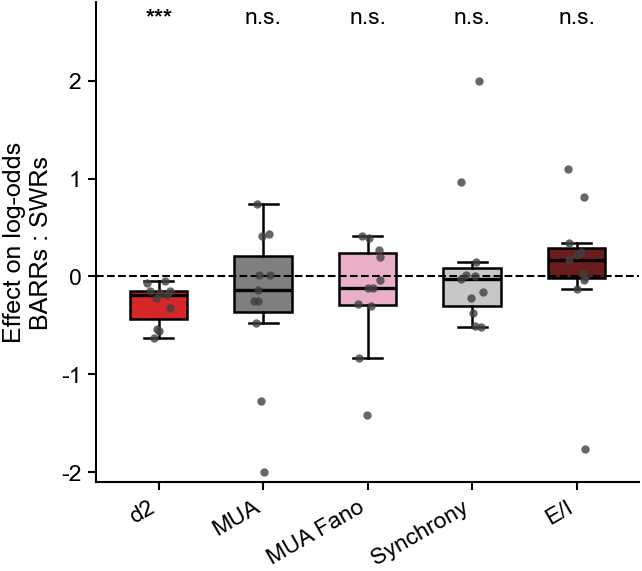

b: |mu|/tau d2 1.32; MUA 0.60; E/I 0.10; MUA Fano 0.06; Synchrony 0.11
c: transfer ratio d2 alone 0.96; MUA alone 0.59; d2 + MUA 0.63; all five 0.37
b brackets, paired session bootstrap, two-sided, Holm-corrected: d2 - MUA_bg p = 0.078; d2 - EI_bg p = 0.002; d2 - fano_bg p = 0.009; d2 - sync_bg p = 0.024


saved figure_output\supplementary\FigS6\FigS6_B_stability_across_epochs.svg / .png


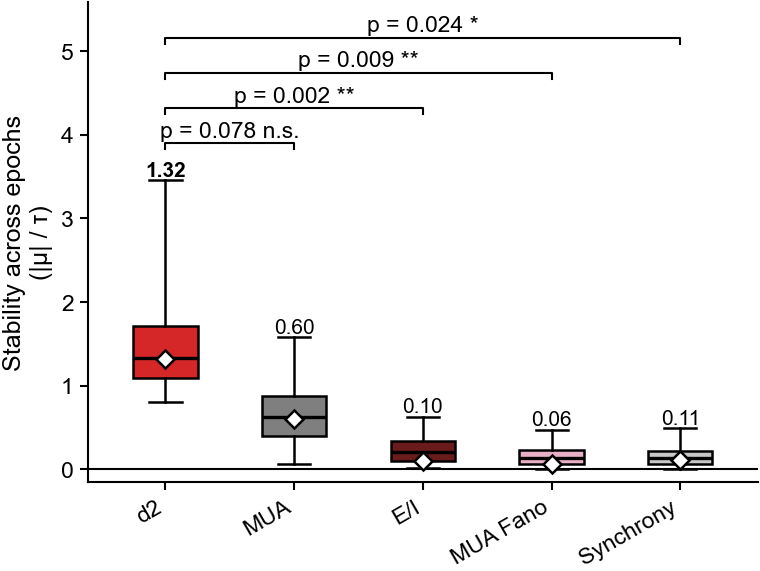

saved figure_output\supplementary\FigS6\FigS6_C_transfer_to_new_session.svg / .png

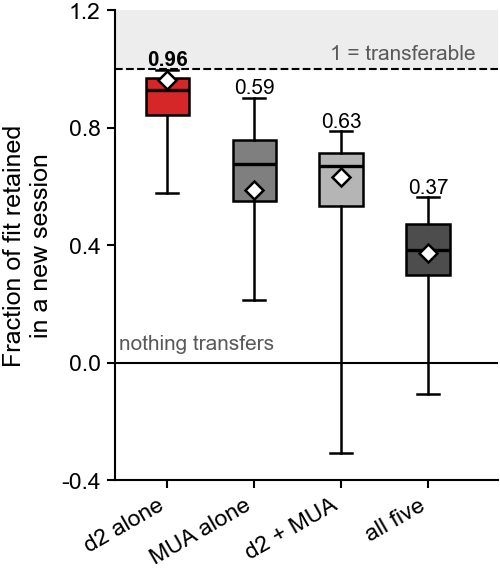

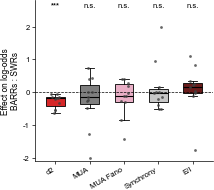

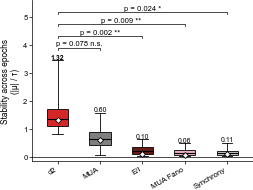

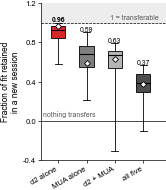

In [2]:
# Supplementary Fig 6 -- d2 as a robust indicator of the NREM CA1 regime: the barrage share of a window's NREM events
# (barrages / (barrages + SWRs)) from the background state between events (every 40 ms bin overlapping a ripple or a
# barrage removed; CA1 units; non-overlapping 30 s NREM windows; barrage cohort, 11 sessions). Colours as Fig. 2's
# GLM (d2 red, MUA grey, the variability measure pink, E/I brown) plus a light grey for synchrony.
COL = {"d2": "#d62728", "MUA": "#7f7f7f", "fano": "#e9afc6", "EI": "#691c1b", "sync": "#c7c7c7"}   # lab: fig2_new RED, GREY, PINK, DARK
key = lambda c: c[:-3] if c.endswith("_bg") else c       # noqa: E731  d2_bg -> d2

# ---- a: one binomial model per session (barrage share of the window's events ~ the five background measures,
# z-scored within session, entered together); coefficient per within-session SD; one-sample signed-rank over sessions
# (lab: r16_block_level_dissociation.py -> r16_event_type_classifier_session{,_summary}.csv)
C = read("a_session_coefficients.csv")
S = read("a_summary.csv").set_index("predictor")
ORDER = ["d2_bg", "MUA_bg", "fano_bg", "sync_bg", "EI_bg"]
LAB = {"d2_bg": "d2", "MUA_bg": "MUA", "fano_bg": "MUA Fano", "sync_bg": "Synchrony", "EI_bg": "E/I"}
for c in ORDER:
    v = C[C.predictor == c].coef
    assert abs(stats.wilcoxon(v).pvalue - S.loc[c, "p_signrank"]) < 1e-9, c
_v = C[C.predictor == "d2_bg"].coef
print(f"a: d2 same sign in {int((np.sign(_v) == np.sign(_v.median())).sum())} of {len(_v)} sessions; one-sample two-sided "
      "Wilcoxon signed-rank: " + "; ".join(f"{LAB[c]} p = {S.loc[c, 'p_signrank']:.2g}" for c in ORDER))
rc("FigS6_A_barrage_share_by_measure", "draw")     # lab: F.final_style()
fig, ax = plt.subplots(figsize=(56 * F.MM, 50 * F.MM), layout="constrained")
YL = (-2.0, 2.0)
rng = np.random.default_rng(1)
for i, c in enumerate(ORDER):
    v = C[C.predictor == c].coef.to_numpy()
    bp = ax.boxplot(v, positions=[i], widths=0.55, showfliers=False, patch_artist=True,
                    medianprops=dict(color="k", lw=0.8), boxprops=dict(lw=0.6), whiskerprops=dict(lw=0.6),
                    capprops=dict(lw=0.6))
    bp["boxes"][0].set_facecolor(COL[key(c)])
    vc = np.clip(v, *YL)
    ax.scatter(i + rng.uniform(-0.12, 0.12, v.size), vc, s=4, color="0.25", alpha=0.8, lw=0, zorder=3)
    r = S.loc[c]
    ax.text(i, 2.75, F.stars(r.p_signrank), ha="center",
            va="top", fontsize=5.5, linespacing=1.1, fontweight="bold" if c == "d2_bg" else "normal")
ax.axhline(0, ls="--", lw=0.5, color="k")
ax.set_ylim(YL[0] - 0.1, 2.8); ax.set_yticks([-2, -1, 0, 1, 2]); ax.set_xlim(-0.6, len(ORDER) - 0.4)
ax.set_xticks(range(len(ORDER))); ax.set_xticklabels([LAB[c] for c in ORDER], rotation=30, ha="right")
ax.set_ylabel("Effect on log-odds\nBARRs : SWRs")      # per within-session SD, NREM: in the legend
rc("FigS6_A_barrage_share_by_measure", "save")
F.settle(fig)
F.drop_counts(fig)
F.show(F.save(fig, "FigS6_A_barrage_share_by_measure"))

# ---- b, c: robustness (lab: r16_robustness_index.py; its bootstrap functions boot_A / boot_B, fixed seed).
# Boxes = the session-level cluster bootstrap of each index (2 000 resamples of the 11
# sessions, blocks travelling with them; resamples a function cannot fit are dropped, so each index has its own n):
# box = IQR, whiskers = 2.5-97.5th percentile; diamond = the full-data estimate.
A = read("b_estimates.csv")
B = read("c_estimates.csv")
Vb, Vc = read("b_bootstrap.csv"), read("c_bootstrap.csv")
VA = {c: g.value.to_numpy() for c, g in Vb.groupby("predictor", sort=False)}
VB = {m: g.value.to_numpy() for m, g in Vc.groupby("model", sort=False)}
print("b: |mu|/tau " + "; ".join(f"{LAB[r.predictor]} {r.mu_over_tau:.2f}" for _, r in A.iterrows()))
print("c: transfer ratio " + "; ".join(f"{r.model} {float(r.transfer_ratio):.2f}" for _, r in B.iterrows()))

# brackets d2 vs each other condition, b only: a PAIRED session bootstrap -- each resample draws one set of 11
# sessions and both indices are computed on it; p = 2 x the smaller tail of the difference around 0, two-sided, Holm
# across the comparisons of the panel (as Fig. 2e); floor 1/2000. (lab: computed in the cell; here its table)
TESTS = read("bracket_tests.csv")
print("b brackets, paired session bootstrap, two-sided, Holm-corrected: "
      + "; ".join(f"{r.comparison} p = {r.p_paired_holm:.3g}" for _, r in TESTS[TESTS.panel == "b"].iterrows()))


def ptxt(p):                                               # as Fig. 2e's brackets: "p = 0.004 **"
    return ("p < 0.001" if p < 0.001 else f"p = {p:.3f}" if p < 0.1 else f"p = {p:.2f}") + f" {F.stars(p)}"


def brackets(ax, comps, y0, dy):                           # b only: p and stars
    for j, (x1, p) in enumerate(comps):
        F.bracket(ax, 0, x1, y0 + j * dy, ptxt(p), h=0.18 * dy, fs=5.5)


def boxes(ax, data, colors, est, bold, labels=None):
    bp = ax.boxplot(data, positions=range(len(data)), widths=0.5, whis=(2.5, 97.5), showfliers=False,
                    patch_artist=True, zorder=2, medianprops=dict(color="k", lw=0.8), whiskerprops=dict(lw=0.6),
                    capprops=dict(lw=0.6), boxprops=dict(lw=0.6))
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
    for i, (v, d) in enumerate(zip(est, data)):
        ax.plot(i, v, "D", ms=3, color="white", mec="k", mew=0.6, zorder=4)
        top = np.percentile(d, 97.5)                    # the value above the upper whisker, clear of the neighbours
        ax.text(i, top, f"{v:.2f}" + (labels[i] if labels else ""), ha="center", va="bottom", fontsize=5,
                fontweight="bold" if bold[i] else "normal")


rc("FigS6_B_stability_across_epochs", "draw")
fig, ax = plt.subplots(figsize=(66 * F.MM, 50 * F.MM), layout="constrained")
preds = list(A.predictor)
boxes(ax, [np.clip(VA[c], 0, 4.5) for c in preds], [COL[key(c)] for c in preds], A.mu_over_tau.to_numpy(),
      [c == "d2_bg" for c in preds])
ax.axhline(0, lw=0.5, color="k")
ax.set_xticks(range(len(preds)))
ax.set_xticklabels([LAB[c] for c in preds], rotation=30, ha="right")   # plain names as a; the residualisation in the legend
ax.set_xlim(-0.6, len(preds) - 0.4)
TB = TESTS[TESTS.panel == "b"]
brackets(ax, [(i + 1, p) for i, p in enumerate(TB.p_paired_holm)], 3.9, 0.42)
ax.set_ylim(-0.15, 3.9 + 4 * 0.42)
ax.set_ylabel("Stability across epochs\n(|μ| / τ)")
# no right axis: Φ(|μ|/τ), the expected fraction of epochs sharing the sign, is in the legend
rc("FigS6_B_stability_across_epochs", "save")
F.show(F.save(fig, "FigS6_B_stability_across_epochs"))

rc("FigS6_C_transfer_to_new_session", "draw")
fig, ax = plt.subplots(figsize=(44 * F.MM, 50 * F.MM), layout="constrained")
CMAP = {"d2 alone": COL["d2"], "MUA alone": COL["MUA"], "d2 + MUA": "#b5b5b5", "all five": "#4d4d4d"}
ax.axhspan(1.0, 2.0, color="0.93", zorder=0)
ax.axhline(1.0, ls="--", lw=0.5, color="k", zorder=1); ax.axhline(0.0, lw=0.5, color="k", zorder=1)
boxes(ax, [VB[m] for m in B.model], [CMAP[m] for m in B.model], B.transfer_ratio.astype(float).to_numpy(),
      [m == "d2 alone" for m in B.model])
ax.text(len(B) - 0.45, 1.02, "1 = transferable", ha="right", va="bottom", fontsize=5, color="0.35")
ax.text(-0.55, 0.03, "nothing transfers", ha="left", va="bottom", fontsize=5, color="0.35")
ax.set_xticks(range(len(B))); ax.set_xticklabels(list(B.model), rotation=30, ha="right")
ax.set_xlim(-0.6, len(B) - 0.2)
# no brackets on c: read descriptively (box and 95 % whiskers)
ax.set_ylim(-0.4, 1.2)
ax.set_yticks([-0.4, 0, 0.4, 0.8, 1.2])
ax.set_ylabel("Fraction of fit retained\nin a new session")      # held-out ÷ in-sample deviance explained: legend
rc("FigS6_C_transfer_to_new_session", "save")
F.show(F.save(fig, "FigS6_C_transfer_to_new_session"))